In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [5]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060242

3300060242.a.depth.txt	3300060242.a.map.txt  ebins	   semibin  vamb
3300060242.a.faa	bins		      ebins_eukcc  stats
3300060242.a.fna	bins_checkm	      metabat	   vacuum


In [4]:
sample_id = "3300060242"#"3300055289" # "3300060242"

df_umap_coords = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/vamb_coords.tsv", 
    sep = '\t'
)
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,Ga0586930_0000001,2.225300,-10.325198,Ga0586930
1,Ga0586930_0000002,2.225490,-10.325366,Ga0586930
2,Ga0586930_0000003,0.335744,9.402485,Ga0586930
3,Ga0586930_0000004,2.224309,-10.324649,Ga0586930
4,Ga0586930_0000005,8.143193,-6.782251,Ga0586930


In [30]:
bins = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vamb/vae_clusters.tsv", 
    sep = '\t', 
    names = ['vamb_bin_id', 'contig_id']
)
bins.head()


,vamb_bin_id,contig_id
0,vae_1,Ga0586930_0074298
1,vae_2,Ga0586930_0015812
2,vae_3,Ga0586930_0030300
3,vae_4,Ga0586930_0086153
4,vae_5,Ga0586930_0028261


In [31]:
vamb_bins = bins

vcounts = vamb_bins.groupby('vamb_bin_id').count()

vcounts = vcounts.to_dict()['contig_id']

In [32]:
df_mmseqs = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.faa.mms2lca",
    sep = '\t'
)

In [33]:
df = pd.merge(
    df_umap_coords, 
    vamb_bins, 
    on = 'contig_id'
)

df['vamb_bin_id'] = df.vamb_bin_id.apply(lambda x: 'none' if vcounts[x] < 75 else x)

df = pd.merge(
    df, 
    df_mmseqs[['contig_id', 'name', 'superkingdom', 'lineage']], 
    on = 'contig_id', 
    how = 'left'
).fillna("None")



print(df.shape)
df.head()

(138562, 8)


,contig_id,umap_0,umap_1,sample,vamb_bin_id,name,superkingdom,lineage
0,Ga0586930_0000001,2.225300,-10.325198,Ga0586930,none,Bacteroidota,Bacteria,Bacteria;FCB group;Bacteroidota/Chlorobiota gr...
1,Ga0586930_0000002,2.225490,-10.325366,Ga0586930,none,Bacteroidota,Bacteria,Bacteria;FCB group;Bacteroidota/Chlorobiota gr...
2,Ga0586930_0000003,0.335744,9.402485,Ga0586930,none,Pseudomonadota,Bacteria,Bacteria;Pseudomonadota
3,Ga0586930_0000004,2.224309,-10.324649,Ga0586930,none,Bacteroidota,Bacteria,Bacteria;FCB group;Bacteroidota/Chlorobiota gr...
4,Ga0586930_0000005,8.143193,-6.782251,Ga0586930,none,Actinomycetes,Bacteria,Bacteria;Terrabacteria group;Actinomycetota;Ac...


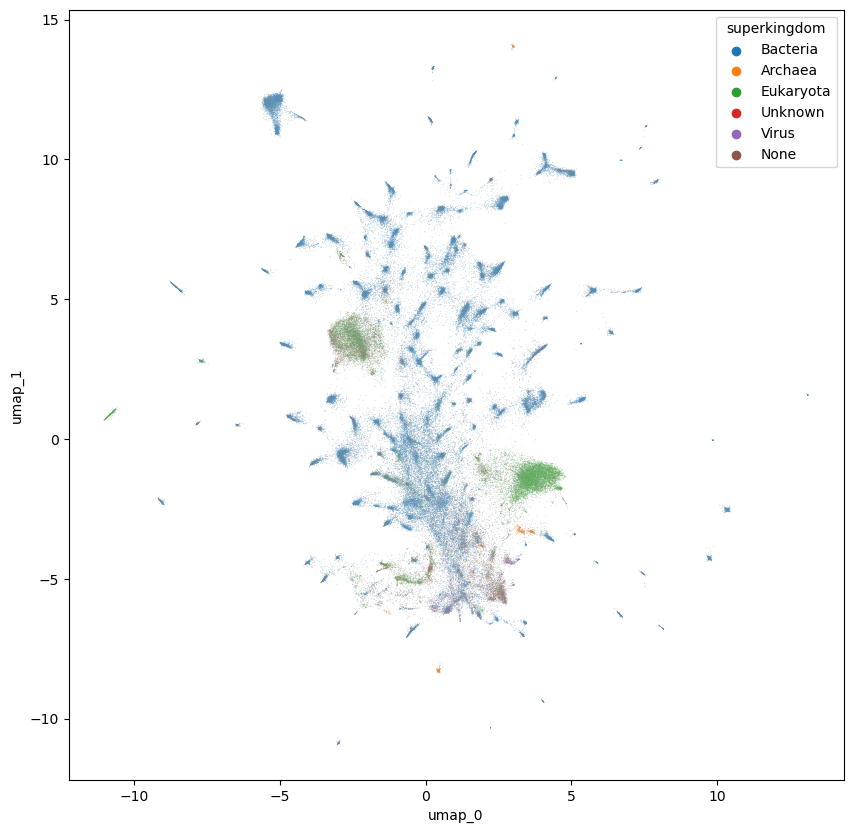

In [34]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'superkingdom', 
    alpha = 0.5
)

In [ ]:
# Don't run below here - processing one bin!
# Bin 1 - Nitzschia - 3300060242

In [66]:
df_nitzschia = df[
    (df.umap_0 < 5) & 
    (df.umap_0 > 2.5) & 
    (df.umap_1 < 0) & 
    (df.umap_1 > -2.5) & 
    (df.superkingdom.isin(["Eukaryota", "Unknown", "None"]))
]

In [53]:
! ls /gpfs/home/qcf21tku/scratch/mosaic_euks_test_tmp/3300060242_90.contigs.txt

/gpfs/home/qcf21tku/scratch/mosaic_euks_test_tmp/3300060242_90.contigs.txt


In [67]:
in_bin = list(pd.read_csv(
    "/gpfs/home/qcf21tku/scratch/mosaic_euks_test_tmp/3300060242_90.contigs.txt", 
    header = None, 
    names = ['contig']
).contig)

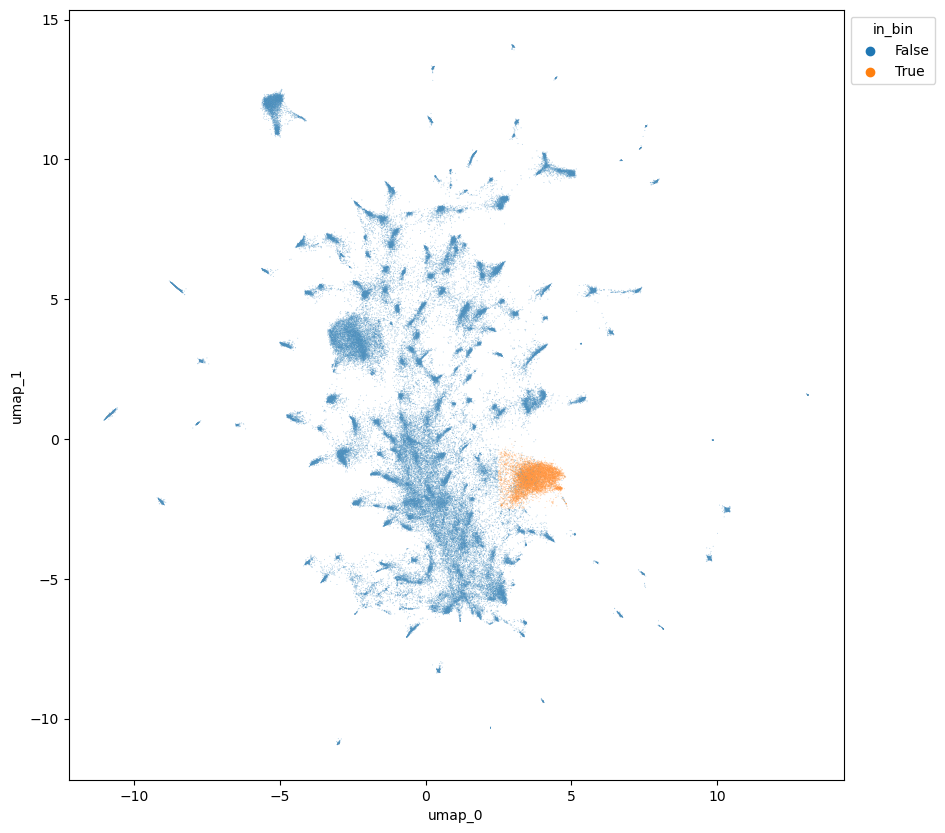

In [68]:
df2 = df
df2['in_bin'] = df2.contig_id.apply(lambda x: x in list(df_nitzschia.contig_id))

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df2,#[df.name_simple != "Unknown"], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'in_bin',
    alpha = 0.35
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [71]:
df_nitzschia[['contig_id']]#.to_csv(
#    "/gpfs/home/qcf21tku/scratch/mosaic_euks_test_tmp/nitzschia_3300060242_v3.contigs.txt", 
#    header = None, 
#    index = None
#)


df2[(df2.in_bin) & (~df2.contig_id.isin(in_bin))]

,contig_id,umap_0,umap_1,sample,vamb_bin_id,name,superkingdom,lineage,in_bin
3419,Ga0586930_0003420,2.749680,-1.042961,Ga0586930,none,None,None,None,True
3699,Ga0586930_0003700,4.034127,-1.226098,Ga0586930,none,Sar,Eukaryota,Eukaryota;Sar,True
3936,Ga0586930_0003937,2.603960,-0.744381,Ga0586930,none,cellular organisms,Unknown,cellular organisms,True
4104,Ga0586930_0004105,3.560928,-1.352434,Ga0586930,none,Sar,Eukaryota,Eukaryota;Sar,True
4248,Ga0586930_0004249,2.927634,-1.130353,Ga0586930,none,Nitzschia inconspicua,Eukaryota,Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacilla...,True
...,...,...,...,...,...,...,...,...,...
138530,Ga0586930_0138531,2.708009,-0.899438,Ga0586930,none,Thalassiosirales,Eukaryota,Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacilla...,True
138534,Ga0586930_0138535,2.969521,-2.221888,Ga0586930,none,Bacillariophyta,Eukaryota,Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacilla...,True
138537,Ga0586930_0138538,3.437038,-1.723141,Ga0586930,none,Attheya septentrionalis,Eukaryota,Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacilla...,True
138538,Ga0586930_0138539,3.751046,-1.776956,Ga0586930,none,Attheya septentrionalis,Eukaryota,Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacilla...,True


In [ ]:
# Below here don't run - this is for processing of one bin!
# Bin 2 - Copopod - 3300055289

df_copopod_bin = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/semibin_cop.1.contigs.txt", 
    names = ['contig_id']
)

df['cpod_bin'] = df.contig_id.isin(df_copopod_bin.contig_id)

In [74]:
from sklearn.decomposition import PCA

In [36]:
emb = np.load("/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289/vamb/latent.npz")["arr_0"]
emb.shape

In [71]:
cop_centre = emb[df[df.cpod_bin].index, :].mean(axis = 0)
df['emb_dist'] = ( np.linalg.norm((emb - cop_centre), axis = 1) < 15 )

In [ ]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'emb_dist', 
    alpha = 0.5
)

In [75]:
pca = PCA(n_components = 32)

cop_pca = pca.fit(emb[df[df.cpod_bin].index, :])

In [90]:
emb2 = pca.transform(emb)

In [110]:
df['emb_dist'] = (df.cpod_bin) | (
    ( np.linalg.norm(emb2, ord = 1, axis = 1) < 75 ) & 
    (df.umap_1 > 3.2) & (df.umap_0 > 5) & (df.umap_0 < 9)
)

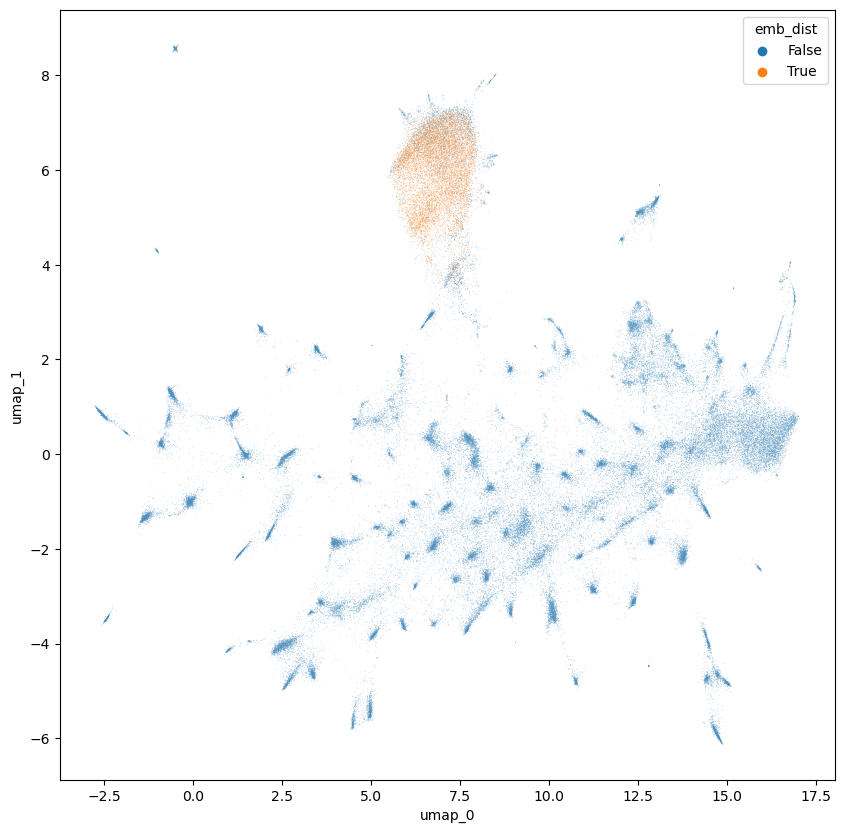

In [111]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'emb_dist', 
    alpha = 0.5
)

In [116]:
df[df.emb_dist][['contig_id']].to_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/semibin_cop.1.v2.contigs.txt", index = False, header = None
)